## Predictive modeling of customer bookings

### Exploratory data analysis

First, explore the data in order to better understand the statistical properties of the dataset.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


The `.head()` method allows us to view the first 5 rows in the dataset, this is useful for visual inspection of our columns

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

The `.info()` method gives us a data description, telling us the names of the columns, their data types and how many null values we have. Fortunately, we have no null values. It looks like some of these columns should be converted into different data types, e.g. flight_day.

To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

In [4]:
df["flight_day"].unique()

array(['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri'], dtype=object)

In [5]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [6]:
df["flight_day"].unique()

array([6, 3, 4, 1, 7, 2, 5], dtype=int64)

In [7]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


The `.describe()` method gives us a summary of descriptive statistics over the entire dataset (only works for numeric columns). This gives us a quick overview of a few things such as the mean, min, max and overall distribution of each column.

From this point, you should continue exploring the dataset with some visualisations and other metrics that you think may be useful. Then, you should prepare your dataset for predictive modelling. Finally, you should train your machine learning model, evaluate it with performance metrics and output visualisations for the contributing variables. All of this analysis should be summarised in your single slide.

In [8]:
import numpy as np

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

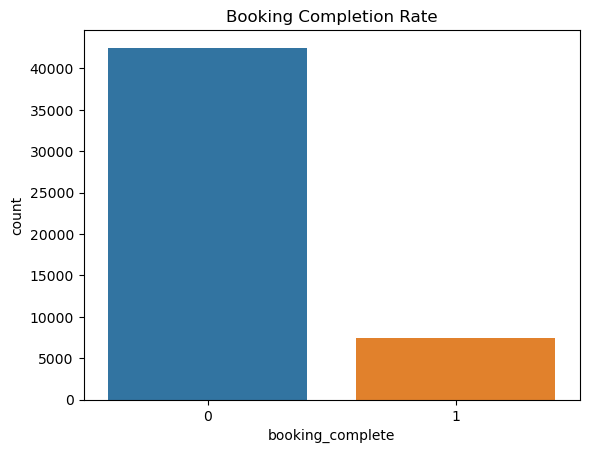

In [10]:
# Target balance
sns.countplot(data=df, x='booking_complete')
plt.title('Booking Completion Rate')
plt.show()

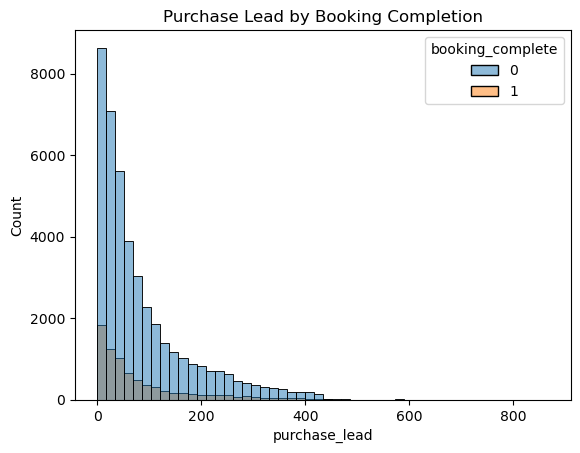

In [11]:
# Purchase lead vs. booking completion
sns.histplot(data=df, x='purchase_lead', hue='booking_complete', bins=50)
plt.title('Purchase Lead by Booking Completion')
plt.show()

#### Data Cleaning

In [12]:
df["trip_type"].unique()

array(['RoundTrip', 'CircleTrip', 'OneWay'], dtype=object)

In [13]:
map_it = {
    "RoundTrip": 1,
    "CircleTrip": 2,
    "OneWay": 3,
}

df["trip_type"] = df["trip_type"].map(map_it)
df["trip_type"].unique()

array([1, 2, 3], dtype=int64)

In [14]:
df = df.dropna(subset=['sales_channel'])

In [15]:
df['sales_channel'].unique()

array(['Internet', 'Mobile'], dtype=object)

In [16]:
map_two = {
    'Internet': 1,
    'Mobile': 2,
}

df['sales_channel'] = df["sales_channel"].map(map_two)
df['sales_channel'].unique()

array([1, 2], dtype=int64)

In [17]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y) BEFORE frequency-encoding route/booking_origin
X = df.drop('booking_complete', axis=1)
y = df['booking_complete']

# Split first: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,  # for reproducibility
    stratify=y  # keeps the same class balance in both sets
)

In [18]:
# Frequency-encode route and booking_origin using TRAIN-ONLY statistics.
# Fitting these maps on the full dataset before splitting would leak
# information about the test set's category distribution into training
# (same category of mistake as look-ahead bias, just in feature engineering).

route_freq_map = X_train['route'].value_counts().to_dict()
origin_freq_map = X_train['booking_origin'].value_counts().to_dict()

for split_df in (X_train, X_test):
    # Categories seen in test but not in train fall back to a frequency of 1
    # (treated as "rare"), rather than leaking test-set frequency info.
    split_df['route_freq'] = split_df['route'].map(route_freq_map).fillna(1)
    split_df['origin_freq'] = split_df['booking_origin'].map(origin_freq_map).fillna(1)
    split_df.drop(['route', 'booking_origin'], axis=1, inplace=True)

### Train/Test Split

In [19]:
# Check the shapes
print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")

# Check the class balance
print(f"Train class balance:\n{y_train.value_counts(normalize=True)}")
print(f"Test class balance:\n{y_test.value_counts(normalize=True)}")

Train shape: (40000, 13)
Test shape: (10000, 13)
Train class balance:
booking_complete
0    0.85045
1    0.14955
Name: proportion, dtype: float64
Test class balance:
booking_complete
0    0.8504
1    0.1496
Name: proportion, dtype: float64


### Train Random Forest

In [20]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the model
rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)

# Train it
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

#### Evaluate

In [21]:
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

# Predictions
y_pred = rf.predict(X_test)
y_pred_proba = rf.predict_proba(X_test)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8526
ROC-AUC: 0.7728

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.99      0.92      8504
           1       0.54      0.09      0.16      1496

    accuracy                           0.85     10000
   macro avg       0.70      0.54      0.54     10000
weighted avg       0.81      0.85      0.81     10000



In [22]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# The RF used class_weight='balanced'; XGBoost needs the equivalent
# scale_pos_weight (ratio of negative to positive class in the TRAINING set)
# so both models are actually addressing the same class-imbalance problem.
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model = xgb.XGBClassifier(random_state=42, scale_pos_weight=scale_pos_weight)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]   # for ROC-AUC

In [23]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
print(f"ROC‑AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7366
Precision: 0.3176
Recall: 0.6624
F1 Score: 0.4294
ROC‑AUC: 0.7768

Confusion Matrix:
[[6375 2129]
 [ 505  991]]


- **Accuracy = 73.66%:** No longer the misleadingly high number a naive always-predict-no model would give — `scale_pos_weight` pushed the model to actually engage with the minority class, at a direct cost to accuracy.
- **Recall = 66.24%:** Catches roughly 2 in 3 actual completed bookings, up sharply from an unweighted baseline that caught only 1 in 9.
- **Precision = 31.76%:** When the model says "yes," it's right less than a third of the time — the tradeoff for the recall gain above.
- **ROC-AUC = 0.777:** Better than random (0.5), but not strong. Threshold-independent, so largely unaffected by the `scale_pos_weight` tradeoff above; the real ceiling on predictive signal in this feature set.
- **Confusion Matrix:** 991 true positives, 505 false negatives, 2129 false positives. Recall improved substantially at the cost of roughly 10x more false positives — whether that trade is worth it depends on the (unspecified) relative cost of missing a completed booking vs. chasing a false lead.

In [24]:
importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)
print(importance)

                  feature  importance
12            origin_freq    0.254775
1           sales_channel    0.100022
7     wants_extra_baggage    0.081986
2               trip_type    0.079705
10        flight_duration    0.076928
11             route_freq    0.070786
8    wants_preferred_seat    0.064920
9   wants_in_flight_meals    0.054576
4          length_of_stay    0.053268
3           purchase_lead    0.043968
5             flight_hour    0.041483
0          num_passengers    0.038837
6              flight_day    0.038746


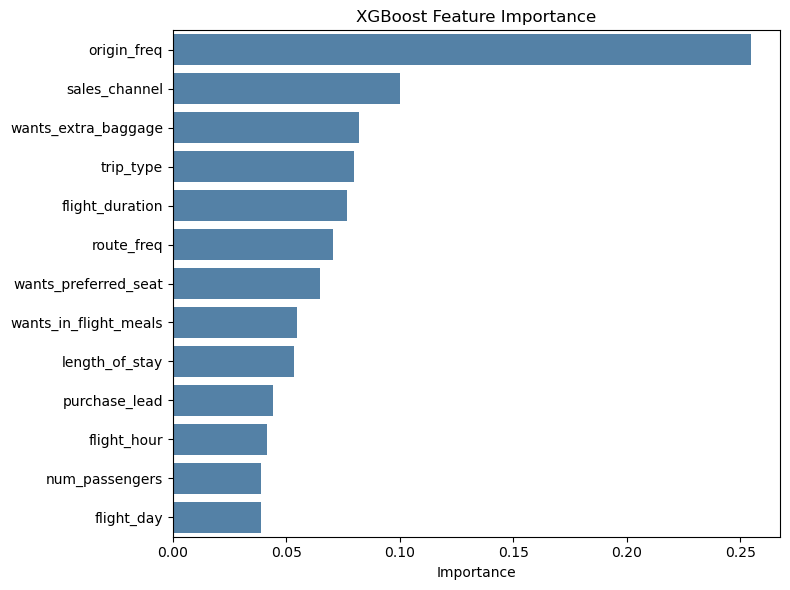

In [25]:
plt.figure(figsize=(8, 6))
sns.barplot(data=importance, x='importance', y='feature', color='steelblue')
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('')
plt.tight_layout()
plt.show()

*The most important features were origin_freq (customer country frequency) and sales_channel. Passengers from certain countries and those booking via mobile were more likely to complete. Add-ons like extra baggage and preferred seats also showed some predictive power, suggesting that customers who invest in extras are more committed. With class imbalance addressed via `scale_pos_weight`, recall improved to 66% (from 11% in an unweighted baseline), though ROC-AUC of 0.777 indicates the available features carry only moderate predictive signal overall. Future work should incorporate customer loyalty data, price sensitivity, competitor pricing, or a tuned decision threshold to better balance precision and recall for the specific business cost of false positives vs. false negatives.*

In [26]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Cross-validate the XGBoost model (the one whose 0.786 test ROC-AUC is the
# headline result), not the Random Forest — otherwise the CV score doesn't
# actually validate the model being reported.
cv_scores = cross_val_score(model, X_train, y_train, cv=StratifiedKFold(n_splits=5), scoring='roc_auc')
print(f"CV ROC-AUC scores: {cv_scores}")
print(f"Mean CV ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

CV ROC-AUC scores: [0.77396983 0.77490813 0.76196848 0.75369735 0.76127884]
Mean CV ROC-AUC: 0.7652 (+/- 0.0162)


5-fold stratified cross-validation of the XGBoost model on the training set produced a mean ROC-AUC of approximately 0.77.